Text(0, 0.5, 'VIX')

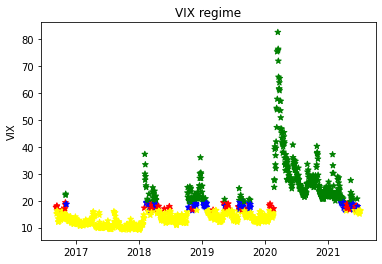

In [1]:
import pandas as pd
import pandas_datareader as pdr
import numpy as np
import matplotlib.pyplot as plt

vix = pdr.DataReader('VIXCLS', 'fred').dropna().squeeze()

lower, upper = 16.5, 19.5

# Each term inside parentheses is [False, True, ...]
# Both terms must be True element-wise for a trigger to occur
blue = (vix < upper) & (vix.shift() >= upper)
yellow = (vix < lower) & (vix.shift() >= lower)
green = (vix > upper) & (vix.shift() <= upper)
red = (vix > lower) & (vix.shift() <= lower)

mapping = {1: 'blue', 2: 'yellow', 3: 'green', 4: 'red'}

indicator = pd.Series(np.where(blue, 1., np.where(yellow, 2.,
                      np.where(green, 3., np.where(red, 4., np.nan)))),
                      index=vix.index).ffill().map(mapping).dropna()

vix = vix.reindex(indicator.index)
plt.scatter(vix.index, vix, c=indicator, marker='*')
plt.title('VIX regime')
plt.ylabel('VIX')